In [ ]:
pip install earthaccess

In [2]:
import geopandas as gpd


c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
counties = gpd.read_file("tl_2024_us_county.zip")

print(counties.head())
print(counties.columns)

  STATEFP COUNTYFP  COUNTYNS  GEOID         GEOIDFQ       NAME  \
0      31      039  00835841  31039  0500000US31039     Cuming   
1      53      069  01513275  53069  0500000US53069  Wahkiakum   
2      35      011  00933054  35011  0500000US35011    De Baca   
3      31      109  00835876  31109  0500000US31109  Lancaster   
4      31      129  00835886  31129  0500000US31129   Nuckolls   

           NAMELSAD LSAD CLASSFP  MTFCC CSAFP CBSAFP METDIVFP FUNCSTAT  \
0     Cuming County   06      H1  G4020   NaN    NaN      NaN        A   
1  Wahkiakum County   06      H1  G4020   NaN    NaN      NaN        A   
2    De Baca County   06      H1  G4020   NaN    NaN      NaN        A   
3  Lancaster County   06      H1  G4020   339  30700      NaN        A   
4   Nuckolls County   06      H1  G4020   NaN    NaN      NaN        A   

        ALAND    AWATER     INTPTLAT      INTPTLON  \
0  1477563042  10772508  +41.9158651  -096.7885168   
1   680980773  61564428  +46.2946377  -123.4244583

In [4]:
# Select only North Carolina
nc = counties[counties["STATEFP"] == "37"]

print(nc[["NAME", "geometry"]])

              NAME                                           geometry
23         Chatham  POLYGON ((-79.24113 35.57054, -79.24138 35.570...
59        Alamance  POLYGON ((-79.26824 35.90918, -79.26791 35.909...
90        Davidson  POLYGON ((-80.39431 35.97276, -80.39417 35.972...
181       Franklin  POLYGON ((-78.12969 36.23955, -78.12958 36.239...
218        Robeson  POLYGON ((-79.12835 34.88294, -79.12795 34.883...
...            ...                                                ...
3113  Transylvania  POLYGON ((-82.79776 35.36129, -82.79772 35.361...
3114         Surry  POLYGON ((-80.44604 36.4546, -80.4464 36.44845...
3156          Clay  POLYGON ((-83.86551 35.12734, -83.8654 35.1275...
3165          Dare  POLYGON ((-75.81311 36.22356, -75.7931 36.2275...
3171      Columbus  POLYGON ((-78.64837 34.46087, -78.64824 34.460...

[100 rows x 2 columns]


In [5]:
western_nc = [
    "Buncombe",
    "Burke",
    "Cherokee",
    "Clay",
    "Graham",
    "Haywood",
    "Henderson",
    "Jackson",
    "Macon",
    "Madison",
    "McDowell",
    "Mitchell",
    "Polk",
    "Rutherford",
    "Swain",
    "Transylvania",
    "Yancey"
]

study_area = nc[nc["NAME"].isin(western_nc)]

print(study_area[["NAME", "geometry"]])

              NAME                                           geometry
304        Madison  POLYGON ((-82.52315 35.79834, -82.52328 35.798...
1010         Swain  POLYGON ((-83.95339 35.46023, -83.95306 35.460...
1287        Graham  POLYGON ((-84.0235 35.41142, -84.02342 35.4115...
1449    Rutherford  POLYGON ((-82.1552 35.52049, -82.15503 35.5204...
1567       Haywood  POLYGON ((-82.8464 35.61442, -82.84619 35.6143...
1720       Jackson  POLYGON ((-83.36377 35.42692, -83.36367 35.427...
1763          Polk  POLYGON ((-82.19966 35.19524, -82.20803 35.195...
1847      Cherokee  POLYGON ((-84.29801 35.16851, -84.298 35.16856...
1868         Macon  POLYGON ((-83.36776 34.99514, -83.36831 34.995...
2106      Mitchell  POLYGON ((-82.41674 36.07283, -82.4166 36.0730...
2282        Yancey  POLYGON ((-82.1453 35.87783, -82.14535 35.8775...
2313         Burke  POLYGON ((-81.94319 35.96005, -81.94296 35.960...
2318      McDowell  POLYGON ((-82.00273 35.55181, -82.00278 35.551...
2823      Buncombe  

<Axes: >

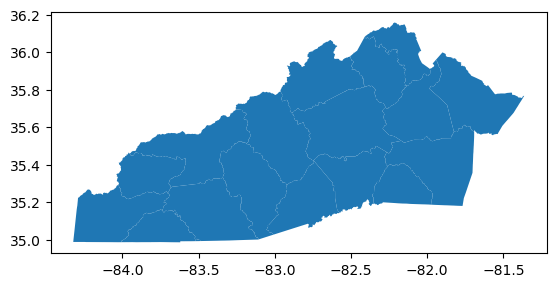

In [6]:
study_area.plot()

In [ ]:

study_area = study_area.to_crs(epsg=4326)

study_area.to_file(
    "western_nc_helene.geojson",
    driver="GeoJSON"
)


GeoJSON created successfully!


In [ ]:
import geopandas as gpd
import earthaccess

study_area = gpd.read_file("western_nc_helene.geojson")
minx, miny, maxx, maxy = study_area.total_bounds

print("West:", minx)
print("South:", miny)
print("East:", maxx)
print("North:", maxy)

# Log into NASA Earthdata
earthaccess.login()

Study area bounds:
West: -84.321821
South: 34.986628
East: -81.363796
North: 36.159057
